In [6]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

sp.init_printing()

Riešime rovnicu $$ \ddot x + \omega_0^2 x + \gamma\dot x = 0 $$ s počiatočnou podmienkou $x(0) = 1$ a $\dot x(0) = 0$.

Obecné analytické riešenia sú
- **Tlmené kmity**, $\gamma < 2\omega_0$ : $$x_1(t) = (A_1\cos(\omega t) + A_2\sin(\omega t))e^{-\gamma t/2},$$ kde $\omega = \sqrt{\omega_0^2 - \gamma^2/4}$
- **Medzný aperiodický pohyb**, $\gamma = 2 \omega_0$ : $$x_2(t) = (B_1 + B_2 t)e^{-\gamma t/2}$$
- **Pretlmený aperiodický pohyb**, $\gamma > 2\omega_0$ : $$x_3(t) = (C_1 e^{\sqrt{\gamma^2/4 - \omega_0^2}t} + C_2 e^{-\sqrt{\gamma^2/4 - \omega_0^2}t}) e^{-\gamma t/2}$$

Konštanty $A, \phi$, $B$ a $C$ sú určené z počiatočných podmienok. Vyriešme najprv problém plne analyticky

In [ ]:
# definice symbolov
w0, gamma, t = sp.symbols('omega_0 gamma t', real=True, positive=True)
A1, A2, B1, B2, C1, C2 = sp.symbols('A_1 A_2 B_1 B_2 C_1 C_2', real=True)
x0 = sp.symbols('x_0', real=True)

In [15]:
x_1 = (A1 * sp.cos(w0*t) + A2  * sp.sin(w0*t)) * sp.exp(-0.5*gamma*t)
x_2 = (B1 + B2*t) * sp.exp(-0.5*gamma*t)
x_3 = (C1*sp.exp(sp.sqrt(0.25*gamma**2 - w0**2)*t) + C2*sp.exp(-sp.sqrt(0.25*gamma**2 - w0**2)*t)) * sp.exp(-0.5*gamma*t)

## Partikulárne riešenie pre tlmené kmity

In [41]:
# pociatocne podmienky pre tlmene kmity
x0_eq1 = sp.Eq(x_1.subs(t, 0), x0)
v0_eq1 = sp.Eq(sp.diff(x_1, t).subs(t, 0), 0)
As = sp.solve([x0_eq1, v0_eq1], [A1, A2])
x_1.subs({A1: As[A1], A2: As[A2]}).simplify()

## Partikulárne riešenie pre medzní aperiodický pohyb

In [42]:
x0_eq2 = sp.Eq(x_2.subs(t, 0), x0)
v0_eq2 = sp.Eq(sp.diff(x_2, t).subs(t, 0), 0)
Bs = sp.solve([x0_eq2, v0_eq2], [B1, B2])
x_2.subs({B1: Bs[B1], B2: Bs[B2]}).simplify()

## Partikulárne riešenie pre pretlmené kmity

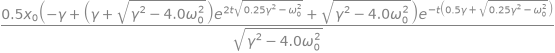

In [43]:
x0_eq3 = sp.Eq(x_3.subs(t, 0), x0)
v0_eq3 = sp.Eq(sp.diff(x_3, t).subs(t, 0), 0)
Cs = sp.solve([x0_eq3, v0_eq3], [C1, C2])
x_3.subs({C1: Cs[C1], C2: Cs[C2]}).simplify()

In [40]:
# prevedime na numericke funkcie
x1_num = sp.lambdify((t, w0, gamma, x0), x_1.subs({A1: As[A1], A2: As[A2]}).simplify(), "scipy")
x2_num = sp.lambdify((t, w0, gamma, x0), x_2.subs({B1: Bs[B1], B2: Bs[B2]}).simplify(), "scipy")
x3_num = sp.lambdify((t, w0, gamma, x0), x_3.subs({C1: Cs[C1], C2: Cs[C2]}).simplify(), "scipy")

## Numerické riešenie

/tmp/ipykernel_103898/3324158742.py:18: RuntimeWarning: invalid value encountered in sqrt
  ax.plot(t, analytical(t, abs(np.sqrt(w0**2 - gamma**2/4)), gamma, 1), ':', color="k")


Text(0, 0.5, 'Výchylka [m]')

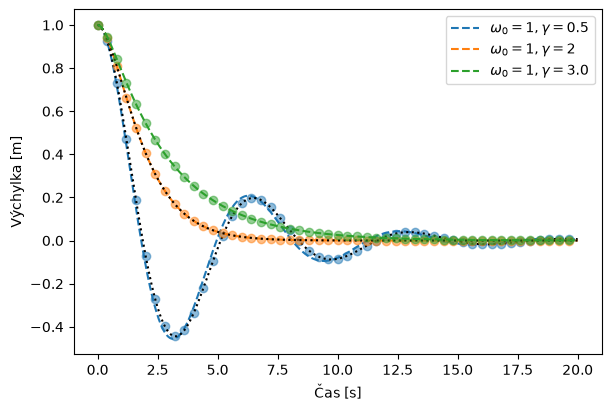

In [66]:
def lho(_t, xv, w0, gamma):
    x, v = xv
    dxdt = v
    dvdt = -w0**2 * x - gamma * v
    return [dxdt, dvdt]

def solve_lho(w0, gamma, x0, t_span, num_points=1000):
    t_eval = np.linspace(t_span[0], t_span[1], num_points)
    sol = solve_ivp(lho, t_span, [x0, 0], args=(w0, gamma), t_eval=t_eval)
    return sol.t, sol.y[0]

fig, ax = plt.subplots(1, 1, figsize=(6, 4), layout='constrained')
t_span = (0, 20)
for i, (w0, gamma, analytical) in enumerate([(1, 0.5, x1_num), (1, 2, x2_num), (1, 3.0, x3_num)]):
    t, x = solve_lho(w0, gamma, x0=1, t_span=t_span)
    p = ax.plot(t[::20], x[::20], 'o', alpha=0.5)
    ax.plot(t, analytical(t, w0, gamma, 1), '--', color=p[0].get_color(), label=fr'$\omega_0={w0}, \gamma={gamma}$')
    ax.plot(t, analytical(t, abs(np.sqrt(w0**2 - gamma**2/4)), gamma, 1), ':', color="k")
    ax.legend()
ax.set_xlabel('Čas [s]')
ax.set_ylabel('Výchylka [m]')